# Day 07: Logistic Regression vs Decision Tree

## Objective
- Compare Logistic Regression and Decision Tree.
- Understand overfitting.
- Apply 5-Fold Cross-Validation.
- Evaluate models using Accuracy, Precision, Recall and F1 Score.

In [11]:

import sys
from pathlib import Path

# Add Day-07 project root to Python path
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

print("Project Root:", project_root)
print("Python path configured successfully!")


Project Root: c:\Users\ASUS\OneDrive\Desktop\20-Day-AI-ML-Internship\Day-07
Python path configured successfully!


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data_loader import load_data
from src.preprocessing import create_preprocessor
from src.train import train_models
from src.evaluate import evaluate_models

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Dataset Loading

In [13]:
df = load_data()

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset loaded successfully!
Dataset Shape: (891, 12)

First 5 Rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C1

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 2. Data Preprocessing

In [14]:
preprocessor = create_preprocessor()

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 3. Model Training


In [15]:
logistic_model, tree_model, X_train, X_test, y_train, y_test = train_models()

print("Both models trained successfully!")

Dataset loaded successfully!
Dataset Shape: (891, 12)

First 5 Rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C1

## 4. Model Evaluation and 5-Fold Cross-Validation

In [16]:
results = evaluate_models()

display(results)

Dataset loaded successfully!
Dataset Shape: (891, 12)

First 5 Rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C1

,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score,Mean CV Accuracy
0,Logistic Regression,0.807584,0.804469,0.793103,0.666667,0.724409,0.796346
1,Decision Tree,0.865169,0.765363,0.754717,0.579710,0.655738,0.803378


## 5. Model Comparison

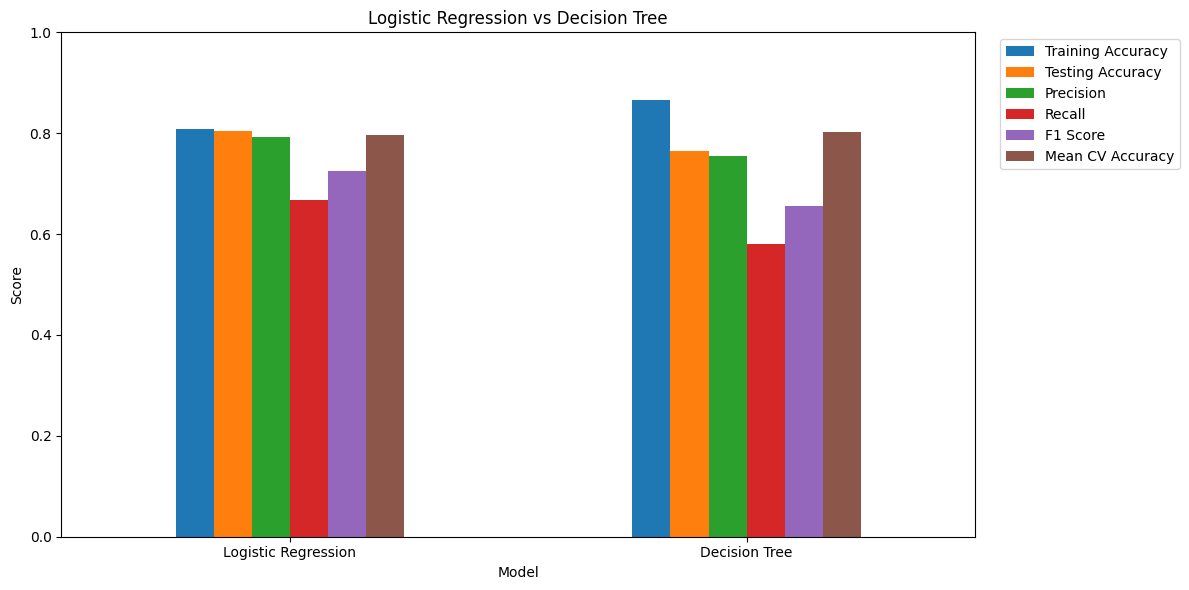

In [17]:
results.set_index("Model")[
    ["Training Accuracy", "Testing Accuracy",
     "Precision", "Recall", "F1 Score", "Mean CV Accuracy"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## 6. Conclusion

In [18]:
print("FINAL MODEL COMPARISON")
display(results)

print("\nBest Model based on Testing Accuracy:")
best_model = results.loc[results["Testing Accuracy"].idxmax(), "Model"]
print(best_model)

print("\nConclusion:")
print("Logistic Regression performed better on the test dataset.")
print("Decision Tree showed signs of possible overfitting.")

FINAL MODEL COMPARISON


,Model,Training Accuracy,Testing Accuracy,Precision,Recall,F1 Score,Mean CV Accuracy
0,Logistic Regression,0.807584,0.804469,0.793103,0.666667,0.724409,0.796346
1,Decision Tree,0.865169,0.765363,0.754717,0.579710,0.655738,0.803378



Best Model based on Testing Accuracy:
Logistic Regression

Conclusion:
Logistic Regression performed better on the test dataset.
Decision Tree showed signs of possible overfitting.
